# LAY'S Final Project

For our final project, we decided to look at three no-so-related submetrics to determine the best neighborhood in Pittsburgh: Air quality, criminal activity, and total PRT Stops (and density). We also considered but ultimately did not go with parks, trails, and EMS stations. <br> <br>
Why didnt we just <b> pick one theme/metric and stick to it? </b> We thought it'd be more interesting to broaden our scope and try to find connections between aspects that at first glance seemed completely unlike each other. After all, when you're picking out a new house, you have to take into account a variety of different things and not just one. <br><br>
Because we were already starting with submetrics, our idea of taking apart the data even further was selecting specific traits of the submetric and working with it (e.g. instead of general health, we picked JUST air quality and looked into that in more detail). Even with these limitations, we were able to find a winning neighborhood! <br><br>
Let's start with air quality.

# Which Pittsburgh Neighborhood Has the Cleanest Air? - Yuki Rai's Submetric
### My submetric: Air Quality

## 1. Introduction
Our group is picking the "best" neighborhood in Pittsburgh. For my individual submetric I chose air quality. Pollution affects respiratory and cardiovascular health and day-to-day quality of life, so a neighborhood with cleaner air is, all else equal, a better place to live.

**What is AQI?** The Air Quality Index is a number from the county's air monitors. **Lower is cleaner.**

| AQI | Meaning |
|---|---|
| 0 to 50 | Good |
| 51 to 100 | Moderate |

**Data:** [Allegheny County Air Quality, Daily AQI (WPRDC)](https://data.wprdc.org/dataset/allegheny-county-air-quality/resource/4ab1e23f-3262-4bd3-adbf-f72f0119108b)

## 2. The Metric: "grading on a curve"
**My first idea didn't work.** I averaged every AQI number at each monitor. But monitors measure *different* pollutants, and some pollutants naturally have bigger numbers. 
**My fix was to grade on a curve.** Each day, I compare a neighborhood to the *rest of the county on that same day*, using the same pollutant.

> **Neighborhood AQI minus county AQI (same day). Below 0 means cleaner than the rest of the county.**

I use the two particle pollutants, **PM2.5 and PM10** (tiny bits of dust and smoke that people breathe in), because the city monitors measure them.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Air_Quality.csv", parse_dates=["date"])

#PM2.5 shows up under several codes (PM25, PM25B, PM25T...), so group them by name
def family(p):
    return "PM25" if p.startswith("PM25") else "PM10" if p.startswith("PM10") else p

df["family"] = df["parameter"].apply(family)
df = df[df["family"].isin(["PM25", "PM10"])]   #keep only the two particle pollutants

### Which air monitors are inside Pittsburgh?
Most monitors are in other towns (Clairton, Avalon, and so on). I matched each monitor's map location to the City of Pittsburgh neighborhood outlines. **Only these four are inside the city**, covering three neighborhoods.

*(Locations come from the Allegheny County Health Department 2018 Annual Network Plan. The monitor named "Pittsburgh" isn't labeled in that plan, so I assumed it is the Manchester monitor.)*

In [10]:
site_to_hood = {
    "Lawrenceville":   "Lower Lawrenceville",
    "Lawrenceville 2": "Lower Lawrenceville",
    "Flag Plaza":      "Crawford-Roberts",
    "Pittsburgh":      "Manchester",   #assumed
}

In [5]:
#one number per site, per day, per pollutant
daily = df.groupby(["date", "family", "site"], as_index=False)["index_value"].mean()

#total and count across ALL monitors each day (so we can get the average of the others)
totals = daily.groupby(["date", "family"])["index_value"].agg(total="sum", n="count").reset_index()

mine = daily[daily["site"].isin(site_to_hood)].merge(totals, on=["date", "family"])
mine = mine[mine["n"] > 1].copy()
mine["hood"] = mine["site"].map(site_to_hood)

#county average of the OTHER monitors = (total - mine) / (n - 1)
mine["county_avg"] = (mine["total"] - mine["index_value"]) / (mine["n"] - 1)
mine["rel_AQI"] = mine["index_value"] - mine["county_avg"]   #below 0 = cleaner than the county

### One example day

In [6]:
ex = mine[(mine["hood"] == "Crawford-Roberts") & (mine["date"] >= "2019-07-01")].iloc[0]
print(f"On {ex['date'].date()}, Crawford-Roberts had a PM10 AQI of {ex['index_value']:.0f}.")
print(f"The other monitors in the county averaged {ex['county_avg']:.1f} that day.")
print(f"Difference: {ex['rel_AQI']:+.1f}  ({'cleaner' if ex['rel_AQI'] < 0 else 'dirtier'} than the county)")
print("\nI repeat this for every day, then average.")

On 2019-07-01, Crawford-Roberts had a PM10 AQI of 17.
The other monitors in the county averaged 25.0 that day.
Difference: -8.0  (cleaner than the county)

I repeat this for every day, then average.


## 3. The Best Neighborhood
Average all the daily differences for each neighborhood, then turn them into a **0 to 1 score** (1 = cleanest) so my group can combine it with the other metrics.

In [7]:
per_pollutant = mine.groupby(["hood", "family"])["rel_AQI"].agg(["mean", "count"])
result = per_pollutant.groupby("hood").agg(rel_AQI=("mean", "mean"), days=("count", "sum")).round(2)
result = result.sort_values("rel_AQI")

#0-1 score: 1 = cleanest, 0 = dirtiest
lo, hi = result["rel_AQI"].min(), result["rel_AQI"].max()
result["air_score"] = ((hi - result["rel_AQI"]) / (hi - lo)).round(2)

result.to_csv("Air_Quality_Scores.csv")   # file to share with my group
result

,rel_AQI,days,air_score
hood,,,
Crawford-Roberts,-5.25,2239,1.00
Manchester,-1.63,4203,0.22
Lower Lawrenceville,-0.63,1557,0.00


### The chart: how much cleaner than the rest of the county?

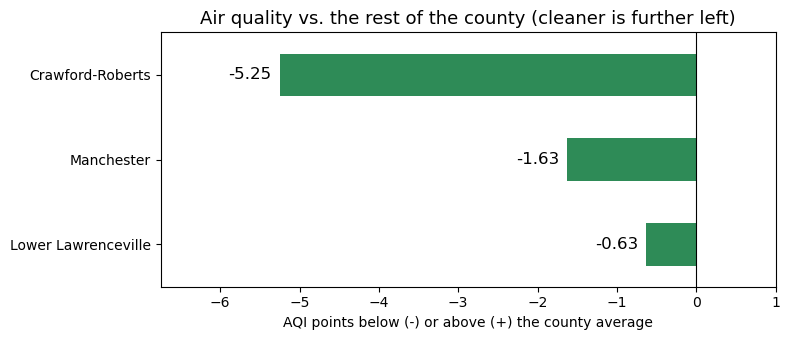

In [8]:
colors = ["#2e8b57" if v < 0 else "#c0392b" for v in result["rel_AQI"]]   # green = cleaner

ax = result["rel_AQI"].plot(kind="barh", color=colors, figsize=(8, 3.5))
for i, v in enumerate(result["rel_AQI"]):
    ax.text(v - 0.1, i, f"{v:+.2f}", va="center", ha="right", fontsize=12)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(result["rel_AQI"].min() - 1.5, 1)
ax.set_title("Air quality vs. the rest of the county (cleaner is further left)", fontsize=13)
ax.set_xlabel("AQI points below (-) or above (+) the county average")
ax.set_ylabel("")
ax.invert_yaxis()   #cleanest on top
plt.tight_layout()
plt.show()

**How to read it:** every neighborhood is *below* 0, so all three had cleaner air than the county average. **The longer the bar, the cleaner the air.** Crawford-Roberts is the cleanest because it has the longest bar.

**Important Limits:**
- Only neighborhoods with an air monitor could be scored, which is just three.
- They aren't measured on exactly the same pollutants or years (Crawford-Roberts: PM10 only, 2016 to early 2022; Lower Lawrenceville: PM2.5 only, mostly 2016 to 2020; Manchester: both, 2020 to now). Comparing each to the county on the same days helps, but it isn't perfect.
- The differences are a few AQI points, so this is a *relative* ranking, not a big gap in health.

## 4. Yuki's Conclusion


After sifting through the data, **Crawford-Roberts** has the cleanest air of the Pittsburgh neighborhoods I could measure, reading on average 5.25 AQI points below the rest of the county on the same days (Manchester was 1.63 below and Lower Lawrenceville 0.63 below). All three neighborhoods were cleaner than the county average, so even the lowest score doesn't mean bad air. Again, this ranking has limits: only three neighborhoods have an air monitor, the monitors cover different pollutants and years, and the gaps are just a few AQI points. Still, the data points to Crawford-Roberts as the best neighborhood for air quality.

# Safety! - Avery Bird's Metric

My sub-metric is safety! The neighborhood with the fewest reported offenses is the safest. My dataset is Monthly Criminal Activity from the WPRDC (Pittsburgh police data, 2024-2026)

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

## Loading the data
I load the Monthly Criminal Activity dataset from the WPRDC (Pittsburgh police data, 2024-2026). The file is criminal_activity.csv.

In [5]:
df = pd.read_csv("criminal_activity.csv", low_memory=False)

print(df.shape)
df.head()

(116730, 21)


,_id,Report_Number,ReportedDate,ReportedTime,Hour,DayofWeek,ReportedMonth,ReportedYear,NIBRS_Coded_Offense,NIBRS_Offense_Code,...,NIBRS_Offense_Type,NIBRS_Crime_Against,NIBRS_Offense_Grouping,Violation,XCOORD,YCOORD,Zone,Tract,Neighborhood,Block_Address
0,1,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,13A AGGRAVATED ASSAULT,13A,...,Aggravated Assault,Person,A,18 2718 A1 Strangulation Basic - Applying,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
1,2,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,13C INTIMIDATION,13C,...,Intimidation,Person,A,18 2706 A1 Terroristic Threats-General,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
2,3,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,90Z ALL OTHER OFFENSES,90Z,...,All other Offenses,Group B,B,75 3733 A Fleeing or Attempting To Elude Polic...,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
3,4,PGHP24000024,2024-01-01,00:31,0,Monday,Jan,2024,23H ALL OTHER LARCENY,23H,...,All Other Larceny,Property,A,18 3921 A Theft by Unlawful Taking-Movable – L...,-80.0268,40.3964,Zone 6,1919,Brookline,"2800 BLOCK OF FITZHUGH WAY PITTSBURGH, PA"
4,5,PGHP24000017,2024-01-01,00:21,0,Monday,Jan,2024,9999 Vehicle Offense (Not NIBRS Reportable),999,...,Not NIBRS Reportable,Group B,B,LO 6 101 Discharge of Firearms Prohibited,-80.0243,40.4582,Zone 1,2107,Manchester,"1200 BLOCK OF COLUMBUS AVE PITTSBURGH, PA"


Before we get into the rankings, let's see what we are working with. Each row in the dataset represents a reported offense, and the dataset includes information like the date, type of offense, and neighborhood where it occurred. It is a LOT of data to sort through though.

## Check the Neighborhood column
Before counting anything, I check the Neighborhood column looking for problems. For example, rows with no neighborhood and how many different neighborhood names there are.  

In [6]:
print(df['Neighborhood'].isna().sum())
print(df['Neighborhood'].nunique())

1259
92


## Cleaning
1,259 had no neighborhood, so I dropped them. I also noticed that two neighborhoods were written using different types of dashes. I got rid of the dashes so each neighborhood had one consistent name. After cleaning, the number of unique neighborhoods went from 92 to 90.

In [7]:
df['Neighborhood'] = df['Neighborhood'].str.strip().str.replace('\u2013', '-', regex=False)
df = df.dropna(subset=['Neighborhood'])

print(len(df))
print(df['Neighborhood'].nunique())


115471
90


## Counting offenses per neighborhood
I count how many offense rows each neighborhood has. value_counts() sorts from most to fewest.

In [8]:
counts = df['Neighborhood'].value_counts()

print(counts.head(10))
print(counts.tail(10))

Neighborhood
Central Business District    13283
South Side Flats              8117
Carrick                       4087
East Liberty                  3590
Shadyside                     3489
East Allegheny                3265
Bloomfield                    2620
Mount Washington              2522
Knoxville                     2495
Squirrel Hill South           2444
Name: count, dtype: int64
Neighborhood
Esplen            194
Oakwood           177
Regent Square     176
Summer Hill       138
Swisshelm Park    113
East Carnegie     104
Chartiers City     88
New Homestead      83
St. Clair          63
Ridgemont          56
Name: count, dtype: int64


## The 10 safest neighborhoods

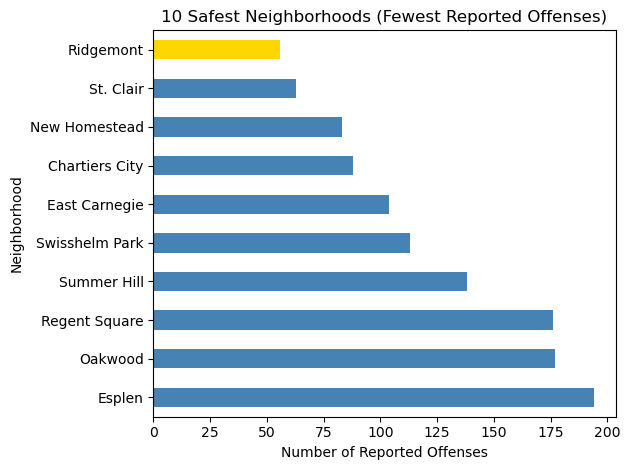

In [11]:
colors = ['steelblue'] * 9 + ['gold']
    
counts.tail(10).plot(kind='barh', color = colors)
plt.title('10 Safest Neighborhoods (Fewest Reported Offenses)')
plt.xlabel('Number of Reported Offenses')
plt.tight_layout()
plt.show()

And we have our top 10! Some neighborhoods have hundreds or even thousands of reported offenses, while others have fewer than 100 across the entire three year period. Ridgemont takes the lead with just 56 reported offenses. 

## Sanity check: 2025 only
Is Ridgemont actually one of the safest neighborhoods, or did it just have one good year? I reran the count on 2025 alone to see whether the same neighborhoods come out safest in a single year.

In [12]:
df_2025 = df[df['ReportedYear'] == 2025]
counts_2025 = df_2025['Neighborhood'].value_counts()

print(counts_2025.tail(10))

Neighborhood
Glen Hazel        62
Esplen            54
Summer Hill       53
East Carnegie     53
Fairywood         50
Swisshelm Park    36
Chartiers City    32
New Homestead     31
Ridgemont         20
St. Clair         10
Name: count, dtype: int64


## Avery's Conclusion
    Based on the data, Ridgemont, with 56 reported offenses from 2024-2026 is the safest neighborhood in Pittsburgh! Not only did it have the fewest overall but if you look at just the year 2025 alone, the same small group of neighborhoods remain amoung the safest: St. Clair, Ridgemont, and New Homestead. Ridgemont's consistency shows that it is not just an outlier in one year but it has actually continued to have very few reported offenses overtime. Its low number of offenses makes it a stand out as the safest neighborhood in Pittsburgh compared to the other neighborhoods. 
    Although, there is one thing to keep in mind, these are raw counts, not rates, so small residential neighborhoods like Ridgemont have an advantage, while neighborhoods like the Central Business District's 13,283 offenses partially reflect how many people pass through downtown. However, based on the numbers collected, Ridgemont is the winner!

# PRT (Bus) Stops - Lily Yakovlev's Submetric
For college students and city-dwellers in general, public transport is THE way to get around. According to the United States Census Bureau, every year over 10% of Pittsburgh residents commute using the Public Regional Transport System, and that's not even counting how many people commute from outside of Pittsburgh. 

I'll be focusing on internal public transport, specifically buses, for my submetric. <br>
Going off of the above, it makes sense for a good neighborhood in Pittsburgh to have abundant bus stops. In this analysis I will be excluding the incline and the light rail because "who decides where to live based on whether or not it has an incline within walking distance??" <br>

We'll use the PRT type and neighborhood columns to sort and analyze the data.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Import my chosen csv
PRT_stops = pd.read_csv("Transit_Stops.csv")

# Show the new dataset assignment was successful
bus_stops = PRT_stops[(PRT_stops["mode"] == "BUS") & (PRT_stops["muni"] == "Pittsburgh city (Allegheny, PA)")][["mode", "hood"]]
bus_stops.head()

,mode,hood
0,BUS,Strip District
1,BUS,Polish Hill
2,BUS,Strip District
3,BUS,Lower Lawrenceville
4,BUS,Central Lawrenceville


I have created a new dataframe from the original that uses two query masks: one that limits the rows to bus stops, and one that limits those rows to Pittsburgh city stops, since I noticed the frame also includes nearby counties.<br>

Now, it's time to start breaking it down!

In [6]:
# Use a dictionary to count how many times each neighborhood appears
dic = {}
for index, row in bus_stops.iterrows():
    neighborhood = row["hood"]

    if neighborhood not in dic:
        dic[neighborhood] = 1
    else:
        dic[neighborhood] += 1
        
# Sort in descending order based on stop count
# Sorted method automatically does this, but we have to use a one-line function to look at the number assigned to each key
dic = dict(sorted(dic.items(), key=lambda item: item[1])[-20:])

for neighborhood in dic:
    print(neighborhood, ":" , dic[neighborhood], "stops")

Marshall-Shadeland : 41 stops
North Oakland : 42 stops
Homewood South : 42 stops
Carrick : 42 stops
Sheraden : 43 stops
South Side Flats : 44 stops
Larimer : 52 stops
Brighton Heights : 53 stops
East Liberty : 63 stops
Central Business District : 63 stops
Perry South : 64 stops
Hazelwood : 69 stops
Brookline : 69 stops
Squirrel Hill South : 70 stops
Greenfield : 71 stops
Squirrel Hill North : 74 stops
Shadyside : 76 stops
Lincoln-Lemington-Belmar : 80 stops
Bloomfield : 89 stops
Mount Washington : 91 stops


Let's graph this out. I'm only doing the top 20 neighborhoods because all 90 would not be readable at all.

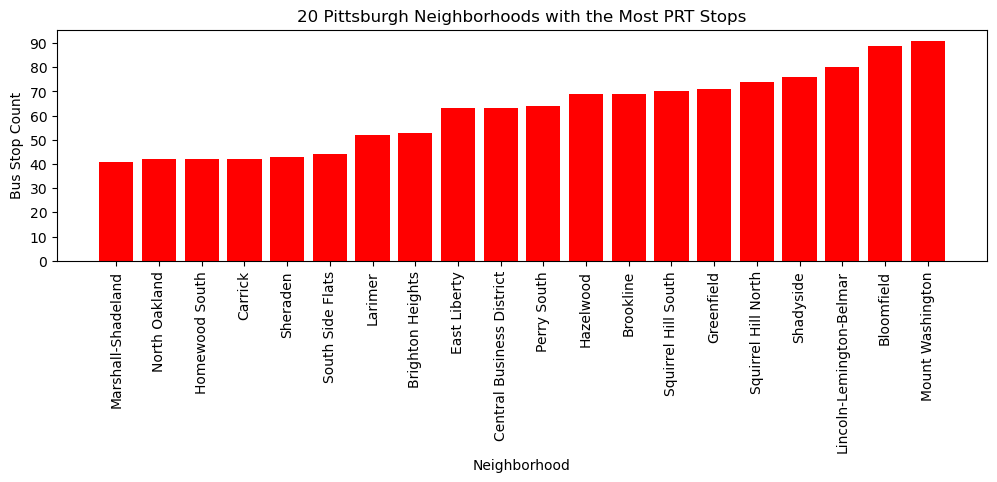

In [5]:
# Use matplotlib keys and values to plot a bar graph of the dictionary
# Replace() used to format neighborhood names such that they don't overlap
neighborhoods = list(dic.keys())[-20:]
stops = list(dic.values())[-20:]

plt.figure(figsize=(12, 3))
plt.bar(neighborhoods, stops, color = "red")
plt.title("20 Pittsburgh Neighborhoods with the Most PRT Stops")
plt.xlabel("Neighborhood")
plt.ylabel("Bus Stop Count")

# Use numpy just to help with formatting
plt.xticks(rotation=90)
plt.yticks(np.arange(0, 100, 10))

plt.show()

Going solely off of the number of bus stops, <b> Mount Washington </b> would be the best neighborhood!

This isn't perfect, though. Is just the number of bus stops in a neighborhood enough to determine if it's convenient to live there? One neighborhood may have 10 versus another with 1, but chances are that first neighborhood is far larger than the second. 

We can take this a step further by looking at neighborhood PRT Bus Stops <b>by square mile.</b>

# PRT Bus Stops Per Square Mile

We'll need to bring in a new dataframe for these calculations. Don't worry, it's a simple one: City of Pittsburgh GIS Data HUB's <b> "Neighborhoods"</b> dataframe. <br>
Luckily, we only need to grab the neighborhood and square mileage columns.

In [16]:
areas = pd.read_csv("Neighborhoods_.csv")[["hood","sqmiles"]]
areas.head()

,hood,sqmiles
0,Point Breeze North,0.301921
1,Squirrel Hill North,1.223409
2,Garfield,0.457385
3,Bedford Dwellings,0.175674
4,Knoxville,0.299625


Now, we can find a more accurate ranking by dividing each neighborhood by its square mileage. We'll do this by dividing the square mileage value for each neighborhood in the dataframe by the matching bus stop dictionary value (the bus stop count). These calculations will be stored in a new dictionary.

In [60]:
ratios = {}
# Bring each neighborhood into the dictionary from the dataframe
# I would reuse the bus stops dictionary above but I think it's more understandable to make a new one
for index, row in bus_stops.iterrows():
    neighborhood = row["hood"]
    
    if neighborhood not in ratios:
        ratios[neighborhood] = 1
    else:
        ratios[neighborhood] += 1

# Get each ratio
# Conveniently, each row/neighborhood only appears once in the areas dataframe, so we don't need to worry about accidentally dividing twice
for index, row in areas.iterrows():
    # Make sure to check each value in dictionary
    for neighborhood in ratios:
        # If they match, divide the stop count by square mileage to find stops per sq. mile
        if neighborhood == row["hood"]:
            ratios[neighborhood] = ratios[neighborhood]/row["sqmiles"]

# Before printing the dictionary, sort in ascending order (copied code from above)
# Only return the last 20
ratios = dict(sorted(ratios.items(), key=lambda item: item[1])[-20:])

# We will also round to the nearest whole bus stop for ease of understanding
for ratio in ratios:
    print(ratio, ":", round(ratios[ratio]), "stops per square mile")

Beltzhoover : 89 stops per square mile
Greenfield : 92 stops per square mile
Manchester : 93 stops per square mile
Morningside : 96 stops per square mile
Knoxville : 97 stops per square mile
Mt. Oliver : 97 stops per square mile
Spring Garden : 97 stops per square mile
Central Business District : 98 stops per square mile
Polish Hill : 105 stops per square mile
Homewood West : 108 stops per square mile
Terrace Village : 108 stops per square mile
East Liberty : 108 stops per square mile
Homewood South : 108 stops per square mile
Larimer : 117 stops per square mile
East Allegheny : 119 stops per square mile
Allegheny Center : 124 stops per square mile
Bloomfield : 127 stops per square mile
West Oakland : 137 stops per square mile
Friendship : 151 stops per square mile
Crawford-Roberts : 163 stops per square mile


Notice how Crawford-Roberts has 163 stops? It sounds wrong, but this just means that if Crawford-Roberts were to be one mile in size, it'd have that many stops. In other words, compared to all the other neighborhoods, it has the most bus stops for its size (41 stops for 0.251 square miles).

Is this extrapolation completely accurate? No, because realistically, a neighborhood of any size could have any number of stops, but it's definitely fun to think about. 

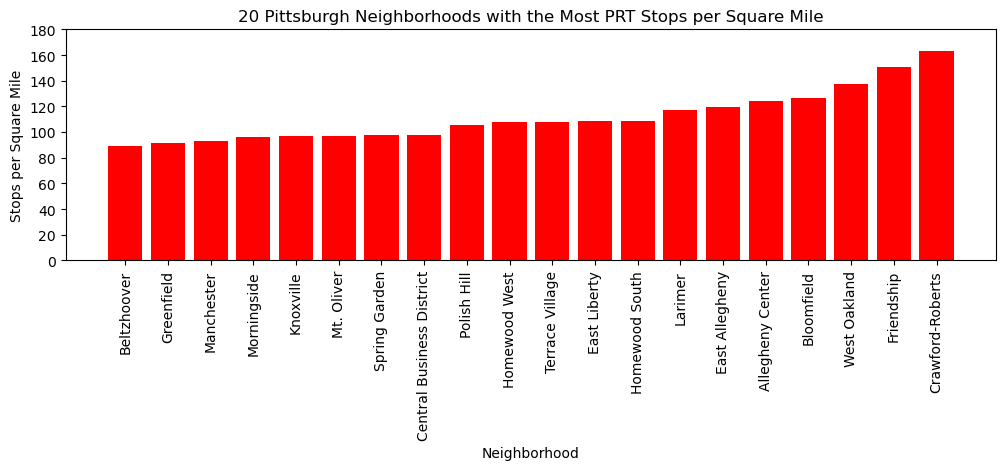

In [66]:
# Copy plotting code from above
neighborhoods = list(ratios.keys())[-20:]
ratio = list(ratios.values())[-20:]

plt.figure(figsize=(12, 3))
plt.bar(neighborhoods, ratio, color = "red")
plt.title("20 Pittsburgh Neighborhoods with the Most PRT Stops per Square Mile")
plt.xlabel("Neighborhood")
plt.ylabel("Stops per Square Mile")

# Use numpy just to help with formatting
plt.xticks(rotation=90)
plt.yticks(np.arange(0, 200, 20))

plt.show()

So, going off of this metric, <b> Crawford-Roberts </b> has the "best" PRT stop density, ensuring for easy travel and minimal movement if you miss a stop!

# Lily's Conclusion
So, after many calculations, it was determined that <b> Mount Washington </b>is the best neighborhood based on bus stop count, and Crawford-Roberts is the best neighborhood by the ratio of bus stops to square mileage. <b> Crawford-Roberts, </b> however, is also outstanding because 91 stops is less meaningful in a 1.1-square-mile-neighborhood than 41 of them in a miniscule 0.251-square-mile one. Mount Washington's statistics are nothing to sneeze at; it has ~81 stops per square mile. It doesn't beat Crawford-Roberts though. I haven't been to either of these neighborhoods, but I'm not surprised Crawford-Roberts came out on top considering geographically it's in the densest part of Pittsburgh City (right next to downtown), whereas Mount Washington is across the river (while still close to the center).

There is a third way we can look at this (which is probably the best way): which neighborhood is the best of both worlds? That'd be <b> Bloomfield, </b> which sits just north of Shadyside and scored second place for most stops overall and fourth for highest bus stop density. I'd say while it is not the top choice for either metric, this one beats out the other two simply because it scores high in both categories tested, making it the safest/most consistent option. 

# Final Analysis
As you've probably noticed by now, a downside of using such different submetrics is that there was not a lot of overlap between our top neighborhoods. <br>

1) <b> Yuki's </b> ranking was Crawford-Roberts, Manchester, and Lower Lawrenceville, with all of them having an air quality ranging from 1 to 5 AQI points lower than the county average (this means their air quality is outstanding)! <b> Crawford-Roberts </b> took the win here, with 5.25 points less than the average. <br>

2) <b> Avery's </b> top neighborhoods were Ridgement, St. Clair, and Homestead with <b> Ridgemont </b> having 53 criminal offenses in the last two years compared to the Central Business District's ~13,000 offenses. Yikes. <b>

3) Finally, <b> Lily </b> found that Mount Washington dominated the other neighborhoods for bus stop count (91), but Crawford-Roberts took the win for density, with about 163 stops per square mile. <b> Bloomfield </b>, however, scored extremely well for both metrics (2nd place and 4th place, respectively), making it the most solid pick overall. <br>

Crawford-Roberts appeared twice here, so that should be our pick, right? Well, unfortunately, it's not very safe. The lack of matches between all three submetrics meant we had to look further and keep going down our lists until one matched up. This is how we landed at <b> Manchester. </b><br>
It sports a good air quality of 1.63 points above average, did not stick out for being unsafe, and sits comfortably within the top 25% of cities for PRT stop density (18th place, to be specific). This makes it a great all-rounder neighborhood for prospective movers!